# Lab 2, variant 11

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, fftshift
from scipy import signal
from scipy.signal import find_peaks, windows

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (10, 3.8)
plt.rcParams["axes.grid"] = True

figures = Path("out/figures")
figures.mkdir(parents=True, exist_ok=True)

## Part A. Window functions in spectral analysis

In [2]:
fs_a = 400
N_a = 2000
f1, f2, f3 = 200, 200.25, 199.75
A1 = 4
A2 = 0.1 * A1
A3 = 0.01 * A1


def tones(fs, N):
    k = np.arange(N)
    x1 = A1 * np.sin(2 * np.pi * f1 / fs * k)
    x2 = A2 * np.sin(2 * np.pi * f2 / fs * k)
    x3 = A3 * np.sin(2 * np.pi * f3 / fs * k)
    return x1, x2, x3


x1, x2, x3 = tones(fs_a, N_a)
x_a = x1 + x2 + x3

print(f"df = fs / N = {fs_a / N_a} Hz, fs/2 = {fs_a / 2} Hz")
print(f"max |x1| = {np.abs(x1).max():.2e}")
print("x2 / A2 == -x3 / A3:", np.allclose(x2 / A2, -x3 / A3))
print(f"max |x| = {np.abs(x_a).max():.4f}, A2 - A3 = {A2 - A3:.4f}")

df = fs / N = 0.2 Hz, fs/2 = 200.0 Hz
max |x1| = 2.76e-12
x2 / A2 == -x3 / A3: True
max |x| = 0.3600, A2 - A3 = 0.3600


### Sampling problem in variant 11

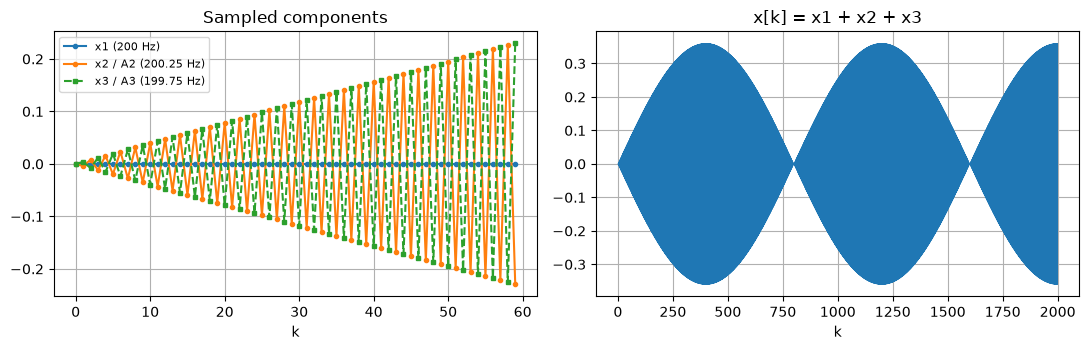

In [3]:
k = np.arange(60)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(k, x1[:60], "C0o-", ms=3, label="x1 (200 Hz)")
ax[0].plot(k, x2[:60] / A2, "C1o-", ms=3, label="x2 / A2 (200.25 Hz)")
ax[0].plot(k, x3[:60] / A3, "C2s--", ms=3, label="x3 / A3 (199.75 Hz)")
ax[0].set_xlabel("k")
ax[0].set_title("Sampled components")
ax[0].legend(fontsize=8)
ax[1].plot(np.arange(N_a), x_a, lw=0.5)
ax[1].set_xlabel("k")
ax[1].set_title("x[k] = x1 + x2 + x3")
fig.tight_layout()
fig.savefig(figures / "win_components.png", dpi=150)
plt.show()

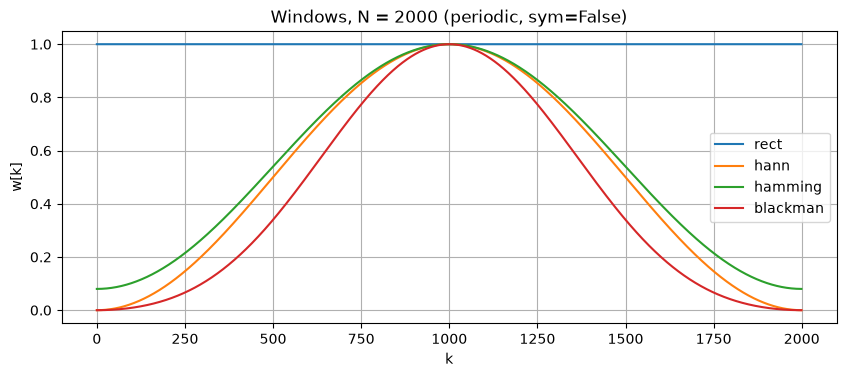

In [4]:
def make_windows(N):
    return {
        "rect": np.ones(N),
        "hann": windows.hann(N, sym=False),
        "hamming": windows.hamming(N, sym=False),
        "blackman": windows.blackman(N, sym=False),
    }


def fft2db(X):
    N = X.size
    level = 2 / N * X
    level[0] /= 2
    if N % 2 == 0:
        level[N // 2] /= 2
    return 20 * np.log10(np.maximum(np.abs(level), 1e-12))


def win_dtft_db(w, zero_padding=100):
    Nz = zero_padding * w.size
    W = np.zeros(Nz)
    W[:w.size] = w
    W = np.abs(fftshift(fft(W)))
    W /= W.max()
    omega = 2 * np.pi / Nz * np.arange(Nz) - np.pi
    return omega, 20 * np.log10(np.maximum(W, 1e-12))


wins_a = make_windows(N_a)
plt.figure()
for name, w in wins_a.items():
    plt.plot(w, label=name)
plt.xlabel("k")
plt.ylabel("w[k]")
plt.title(f"Windows, N = {N_a} (periodic, sym=False)")
plt.legend()
plt.savefig(figures / "win_time.png", dpi=150, bbox_inches="tight")
plt.show()

### DFT spectra of the variant 11 signal

rect      peak at 199.80 Hz, level -9.74 dB
hann      peak at 199.80 Hz, level -15.24 dB
hamming   peak at 199.80 Hz, level -14.66 dB
blackman  peak at 199.80 Hz, level -16.67 dB


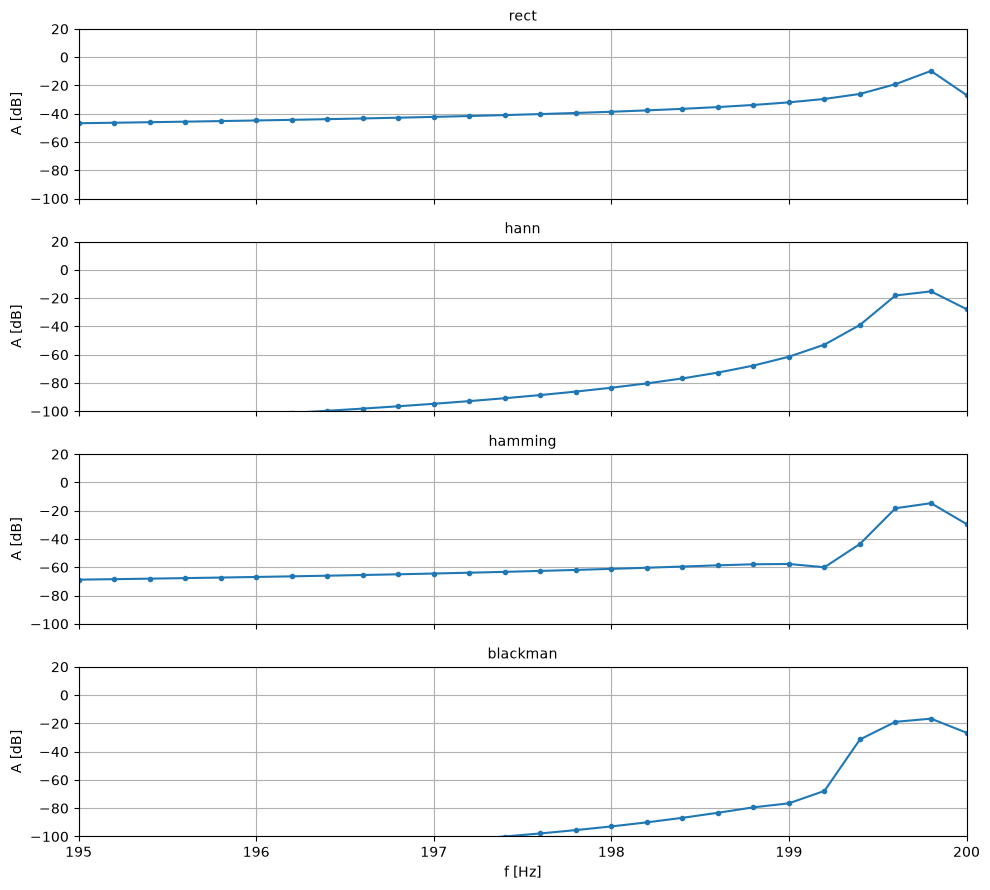

expected level of one tone A = 0.36: -8.87 dB (without window loss)


In [5]:
f_a = np.arange(N_a) * fs_a / N_a
fig, ax = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for axis, (name, w) in zip(ax, wins_a.items()):
    level = fft2db(fft(x_a * w))
    axis.plot(f_a, level, "C0o-", ms=3)
    axis.set_xlim(195, 200)
    axis.set_ylim(-100, 20)
    axis.set_ylabel("A [dB]")
    axis.set_title(name, fontsize=10)
    peak = np.argmax(level[:N_a // 2 + 1])
    print(f"{name:9s} peak at {f_a[peak]:.2f} Hz, level {level[peak]:.2f} dB")
ax[-1].set_xlabel("f [Hz]")
fig.tight_layout()
fig.savefig(figures / "win_spectra_variant.png", dpi=150)
plt.show()

print(f"expected level of one tone A = {A2 - A3:.2f}: "
      f"{20 * np.log10(A2 - A3):.2f} dB (without window loss)")

### DTFT spectra of the windows

window     -3 dB width  null width  max sidelobe
rect           0.90 bins     2.00 bins      -13.3 dB
hann           1.46 bins     4.00 bins      -31.5 dB
hamming        1.32 bins     4.00 bins      -42.7 dB
blackman       1.66 bins     6.00 bins      -58.1 dB


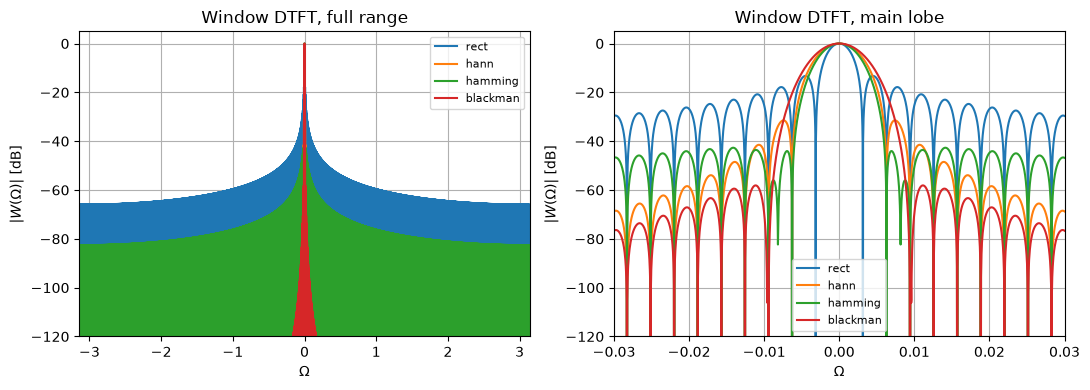

In [6]:
def window_properties(omega, W, N):
    centre = np.argmax(W)
    right = W[centre:]
    minima, _ = find_peaks(-right)
    first_null = minima[0]
    bw3 = np.argmax(right < -3.01)
    bins = N / (2 * np.pi) * (omega[1] - omega[0])
    return 2 * bw3 * bins, 2 * first_null * bins, right[first_null:].max()


fig, ax = plt.subplots(1, 2, figsize=(11, 4))
print(f"{'window':9s} {'-3 dB width':>12s} {'null width':>11s} "
      f"{'max sidelobe':>13s}")
for name, w in wins_a.items():
    omega, W = win_dtft_db(w)
    ax[0].plot(omega, W, label=name)
    ax[1].plot(omega, W, label=name)
    bw3, null, side = window_properties(omega, W, N_a)
    print(f"{name:9s} {bw3:9.2f} bins {null:8.2f} bins {side:10.1f} dB")
ax[0].set_xlim(-np.pi, np.pi)
ax[1].set_xlim(-0.03, 0.03)
for axis in ax:
    axis.set_ylim(-120, 5)
    axis.set_xlabel(r"$\Omega$")
    axis.set_ylabel(r"$|W(\Omega)|$ [dB]")
    axis.legend(fontsize=8)
ax[0].set_title("Window DTFT, full range")
ax[1].set_title("Window DTFT, main lobe")
fig.tight_layout()
fig.savefig(figures / "win_dtft.png", dpi=150)
plt.show()

### Comparison experiment: the same tones without aliasing

In [7]:
def compare(fs, N, name):
    x = sum(tones(fs, N))
    f = np.arange(N) * fs / N
    sel = (f > 199.5) & (f < 200.5)
    fig, ax = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
    print(f"fs = {fs} Hz, N = {N}, df = {fs / N:.4g} Hz")
    for axis, (wname, w) in zip(ax, make_windows(N).items()):
        level = fft2db(fft(x * w))
        axis.plot(f[sel], level[sel], "C0.-", ms=3)
        for tone in (f3, f1, f2):
            axis.axvline(tone, color="r", ls=":", lw=1)
        axis.set_ylim(-80, 20)
        axis.set_ylabel("A [dB]")
        axis.set_title(wname, fontsize=10)
        peaks, _ = find_peaks(level[sel], prominence=3)
        found = ", ".join(f"{f[sel][p]:.2f} Hz ({level[sel][p]:.1f} dB)"
                          for p in peaks)
        print(f"  {wname:9s} {found}")
    ax[-1].set_xlabel("f [Hz]")
    fig.suptitle(f"fs = {fs} Hz, N = {N} (red lines: f3, f1, f2)")
    fig.tight_layout()
    fig.savefig(figures / f"win_compare_{name}.png", dpi=150)
    plt.show()


for A, nm in [(A1, "A1"), (A2, "A2"), (A3, "A3")]:
    print(f"{nm} = {A:5.2f} -> {20 * np.log10(A):6.1f} dB")

A1 =  4.00 ->   12.0 dB
A2 =  0.40 ->   -8.0 dB
A3 =  0.04 ->  -28.0 dB


fs = 800 Hz, N = 8000, df = 0.1 Hz
  rect      199.70 Hz (-26.3 dB), 200.00 Hz (12.0 dB), 200.30 Hz (-11.8 dB)
  hann      200.00 Hz (6.0 dB)
  hamming   200.00 Hz (6.7 dB)
  blackman  200.00 Hz (4.5 dB)


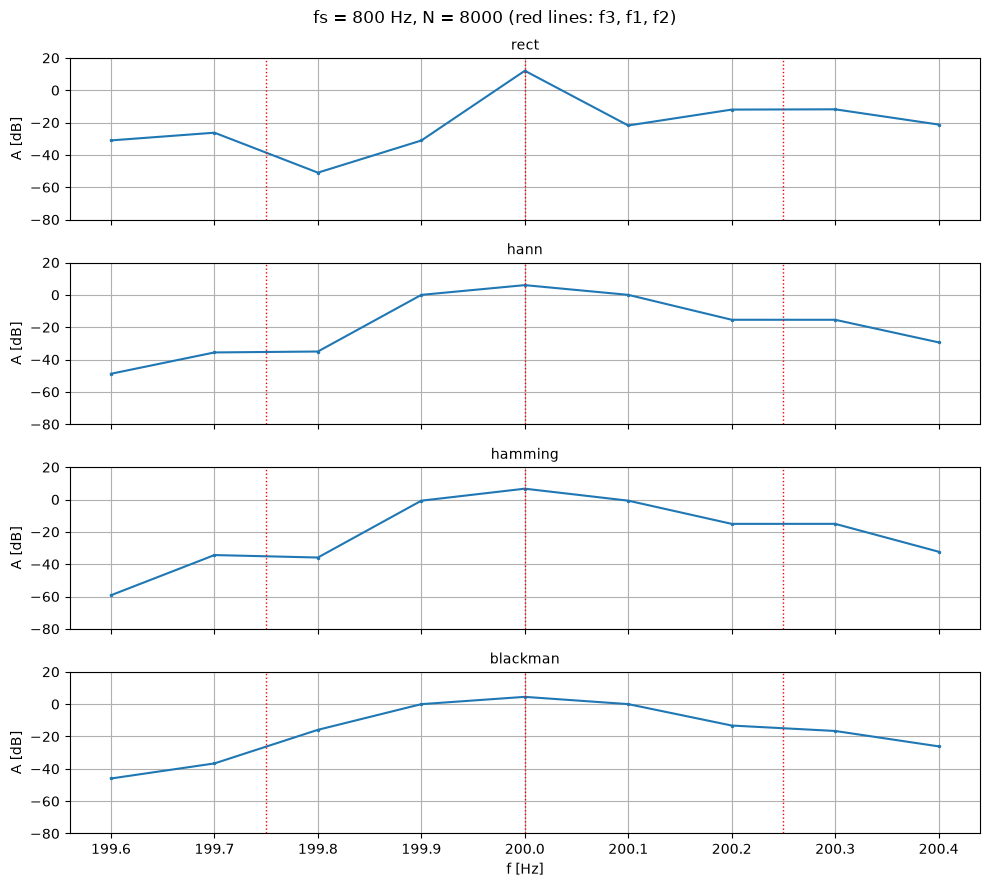

In [8]:
compare(800, 8000, "N8000")

fs = 800 Hz, N = 12002, df = 0.06666 Hz
  rect      199.97 Hz (8.2 dB)
  hann      200.03 Hz (4.6 dB), 200.23 Hz (-13.8 dB)
  hamming   199.70 Hz (-31.2 dB), 199.97 Hz (4.9 dB), 200.23 Hz (-14.2 dB)
  blackman  200.03 Hz (3.4 dB), 200.23 Hz (-15.7 dB)


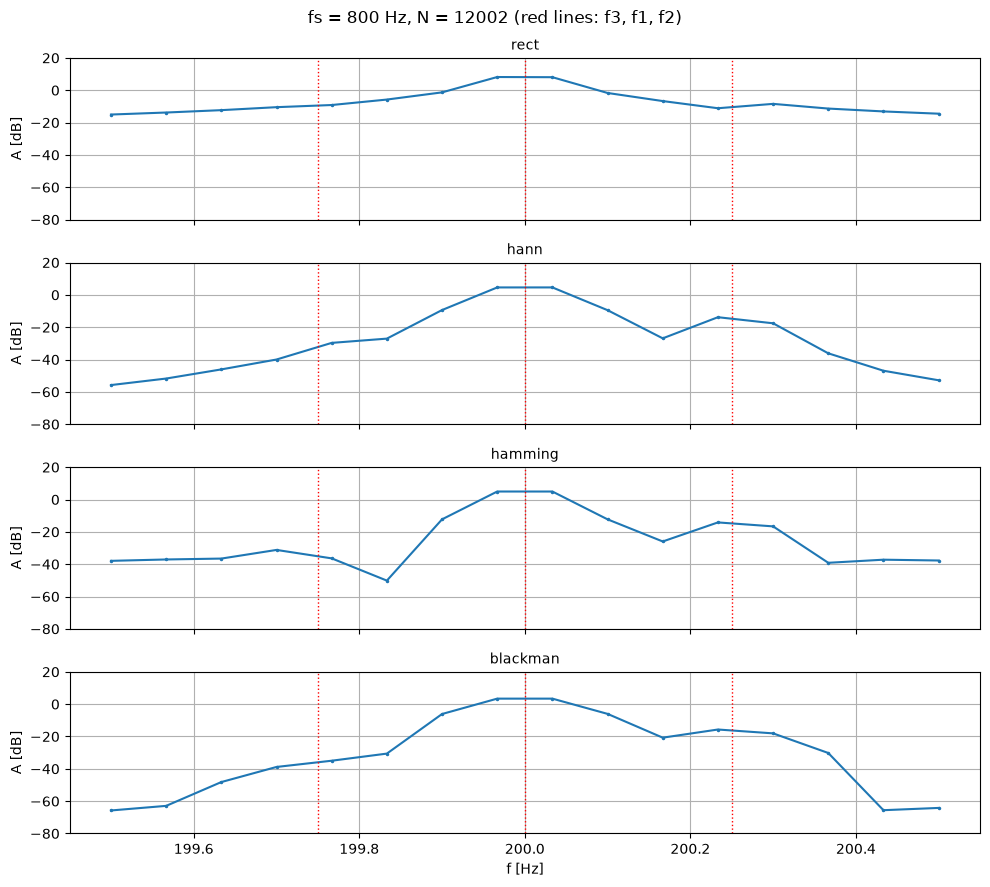

In [9]:
compare(800, 12002, "N12002")

fs = 800 Hz, N = 40002, df = 0.02 Hz
  rect      199.99 Hz (8.1 dB), 200.25 Hz (-7.7 dB)
  hann      199.75 Hz (-34.0 dB), 200.01 Hz (4.6 dB), 200.25 Hz (-14.0 dB)
  hamming   199.75 Hz (-32.8 dB), 199.91 Hz (-36.0 dB), 200.01 Hz (4.9 dB), 200.09 Hz (-36.0 dB), 200.25 Hz (-13.3 dB)
  blackman  199.75 Hz (-35.5 dB), 200.01 Hz (3.4 dB), 200.25 Hz (-15.5 dB)


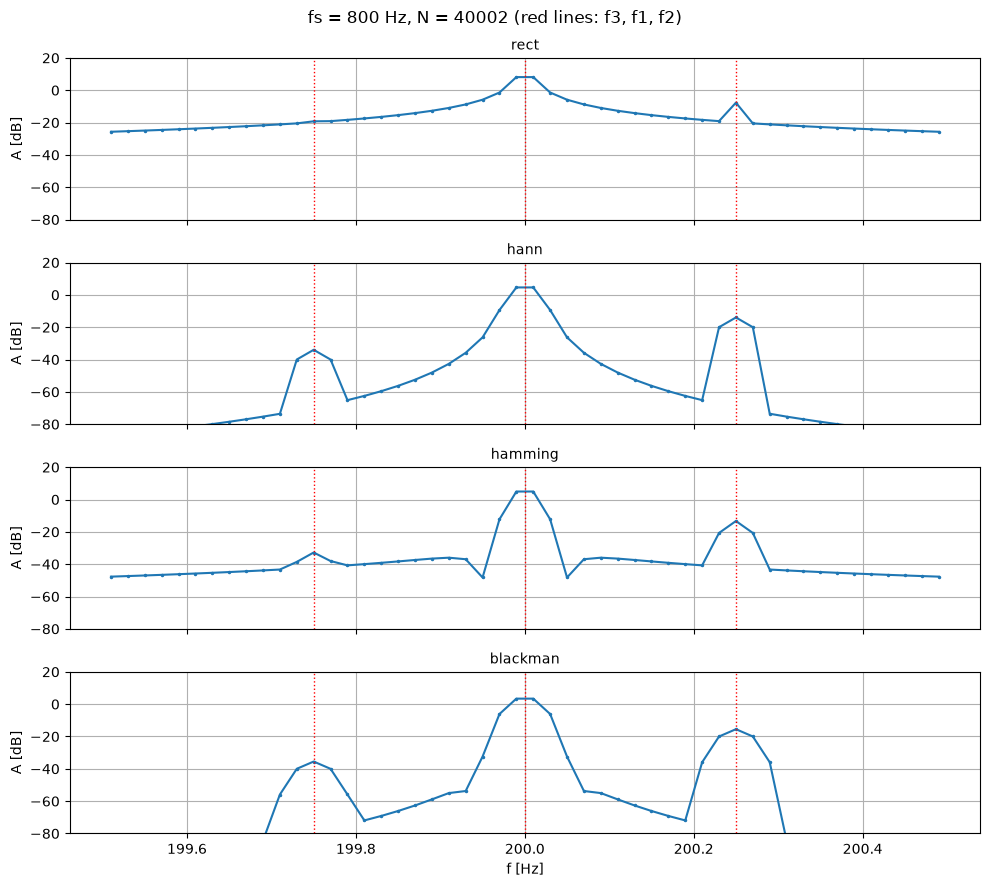

In [10]:
compare(800, 40002, "N40002")

## Part B. Digital filter design and adaptive filtering

### Test signal

input SNR: 3.00 dB
input MSE: 0.2505


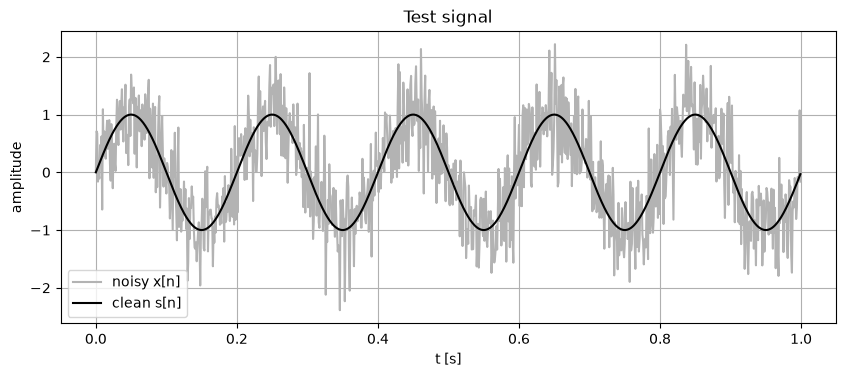

In [11]:
fs = 1000
f0 = 5
sigma = 0.5

t = np.arange(fs) / fs
rng = np.random.default_rng(11)
s = np.sin(2 * np.pi * f0 * t)
v = sigma * rng.standard_normal(fs)
x = s + v


def snr_db(clean, noise):
    return 10 * np.log10(np.mean(clean**2) / np.mean(noise**2))


print(f"input SNR: {snr_db(s, v):.2f} dB")
print(f"input MSE: {np.mean((x - s)**2):.4f}")

plt.plot(t, x, color="0.7", label="noisy x[n]")
plt.plot(t, s, "k", lw=1.5, label="clean s[n]")
plt.xlabel("t [s]")
plt.ylabel("amplitude")
plt.title("Test signal")
plt.legend()
plt.savefig(figures / "signal.png", dpi=150, bbox_inches="tight")
plt.show()

### Implementation

In [12]:
def fir_filter(x, b):
    y = np.zeros(len(x))
    for n in range(len(x)):
        for k in range(len(b)):
            if n - k >= 0:
                y[n] += b[k] * x[n - k]
    return y


def iir_filter(x, b, a):
    y = np.zeros(len(x))
    for n in range(len(x)):
        acc = 0.0
        for k in range(len(b)):
            if n - k >= 0:
                acc += b[k] * x[n - k]
        for k in range(1, len(a)):
            if n - k >= 0:
                acc -= a[k] * y[n - k]
        y[n] = acc / a[0]
    return y


def lms_filter(x, d, mu, M):
    w = np.zeros(M)
    y = np.zeros(len(x))
    e = np.zeros(len(x))
    history = np.zeros((len(x), M))
    for n in range(M - 1, len(x)):
        u = x[n - M + 1:n + 1][::-1]
        y[n] = w @ u
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * u
        history[n] = w
    return y, e, w, history

In [13]:
b_fir = np.array([1, -0.2, 0.5])
b_iir = np.array([0.6, 0.3])
a_iir = np.array([1, 0.4])
mu = 0.05
M = 6

y_fir = fir_filter(x, b_fir)
y_iir = iir_filter(x, b_iir, a_iir)

ref_fir = signal.lfilter(b_fir, [1], x)
ref_iir = signal.lfilter(b_iir, a_iir, x)
print("FIR matches lfilter:", np.allclose(y_fir, ref_fir))
print("IIR matches lfilter:", np.allclose(y_iir, ref_iir))

FIR matches lfilter: True
IIR matches lfilter: True


### Helper: frequency response and filter metrics

In [14]:
w0 = 2 * np.pi * f0 / fs


def gain(b, a, omega):
    _, h = signal.freqz(b, a, worN=[omega])
    return h[0]


def plot_response(b, a, title, name):
    omega, h = signal.freqz(b, a, worN=2048)
    f = omega * fs / (2 * np.pi)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(f, 20 * np.log10(np.abs(h)))
    ax[0].axvline(f0, color="r", ls="--", lw=1, label=f"f0 = {f0} Hz")
    ax[0].set_xlabel("f [Hz]")
    ax[0].set_ylabel("|H| [dB]")
    ax[0].set_title(f"{title}: magnitude")
    ax[0].legend()
    ax[1].plot(f, np.degrees(np.unwrap(np.angle(h))))
    ax[1].set_xlabel("f [Hz]")
    ax[1].set_ylabel("phase [deg]")
    ax[1].set_title(f"{title}: phase")
    fig.tight_layout()
    fig.savefig(figures / f"{name}_response.png", dpi=150)
    plt.show()


def plot_output(y, title, name):
    plt.plot(t, x, color="0.8", label="noisy x[n]")
    plt.plot(t, y, "C0", lw=1.2, label="filtered y[n]")
    plt.plot(t, s, "k", lw=1.5, label="clean s[n]")
    plt.xlabel("t [s]")
    plt.ylabel("amplitude")
    plt.title(title)
    plt.legend(loc="upper right")
    plt.savefig(figures / f"{name}_output.png", dpi=150, bbox_inches="tight")
    plt.show()

### FIR filter, $b = \{1, -0.2, 0.5\}$

impulse response: [ 1.  -0.2  0.5  0.   0.   0.   0.   0.   0.   0. ]
|H| at 0 Hz:    1.3000
|H| at 5 Hz:    1.2994
|H| at fs/2:    1.7000
noise power gain sum(b^2): 1.2900


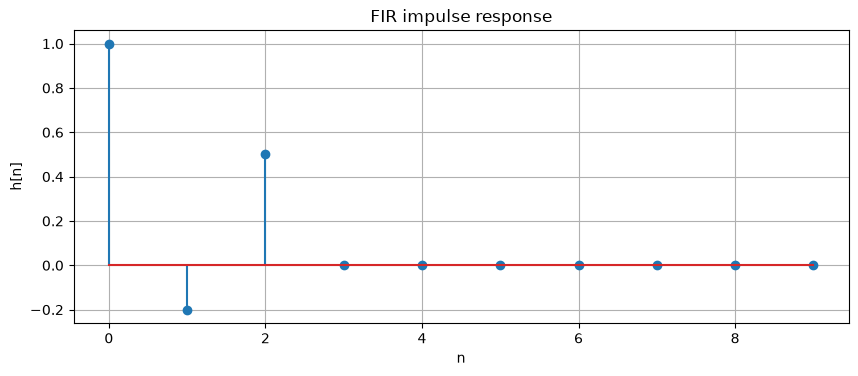

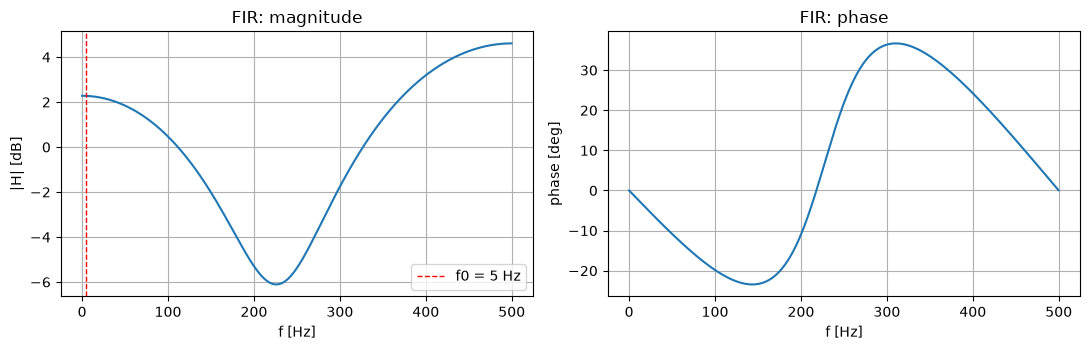

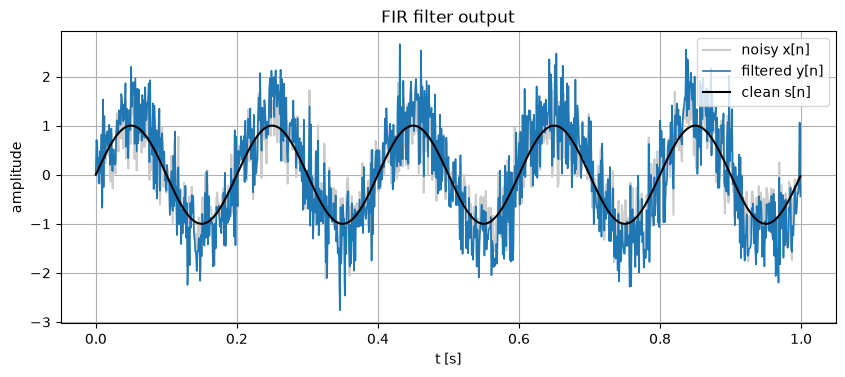

In [15]:
h_fir = fir_filter(np.r_[1, np.zeros(9)], b_fir)
print("impulse response:", h_fir)
print(f"|H| at 0 Hz:    {abs(gain(b_fir, [1], 0)):.4f}")
print(f"|H| at {f0} Hz:    {abs(gain(b_fir, [1], w0)):.4f}")
print(f"|H| at fs/2:    {abs(gain(b_fir, [1], np.pi)):.4f}")
print(f"noise power gain sum(b^2): {np.sum(b_fir**2):.4f}")

plt.stem(np.arange(10), h_fir)
plt.xlabel("n")
plt.ylabel("h[n]")
plt.title("FIR impulse response")
plt.show()

plot_response(b_fir, [1], "FIR", "fir")
plot_output(y_fir, "FIR filter output", "fir")

### IIR filter, $b = \{0.6, 0.3\}$, $a = \{1, 0.4\}$

poles: [-0.4]  |p| = [0.4]
zeros: [-0.5]
stable: True
impulse response (first 8): [ 0.6     0.06   -0.024   0.0096 -0.0038  0.0015 -0.0006  0.0002]
|H| at 0 Hz:    0.6429
|H| at 5 Hz:    0.6429
|H| at fs/2:    0.5000
noise power gain sum(h^2): 0.3643


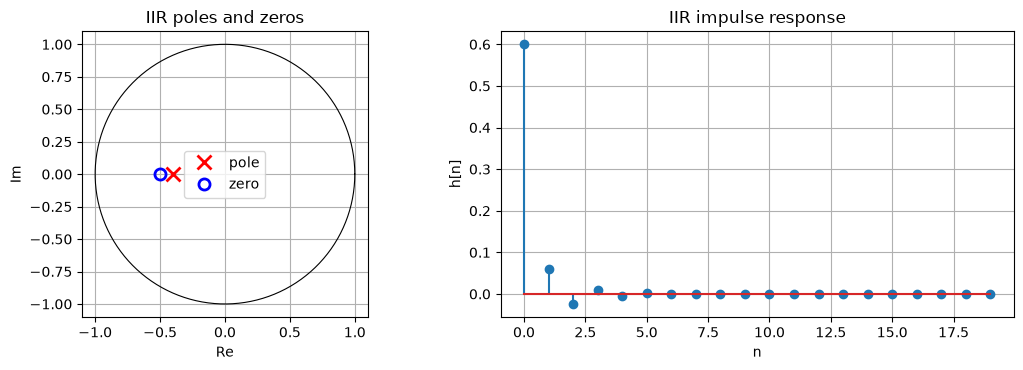

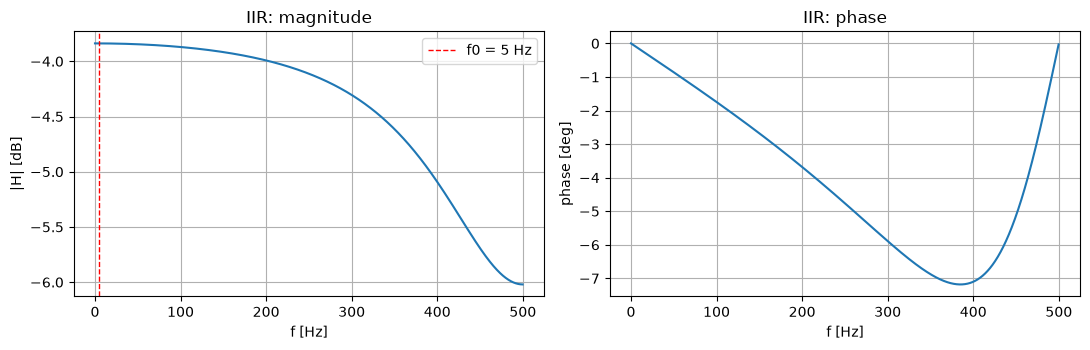

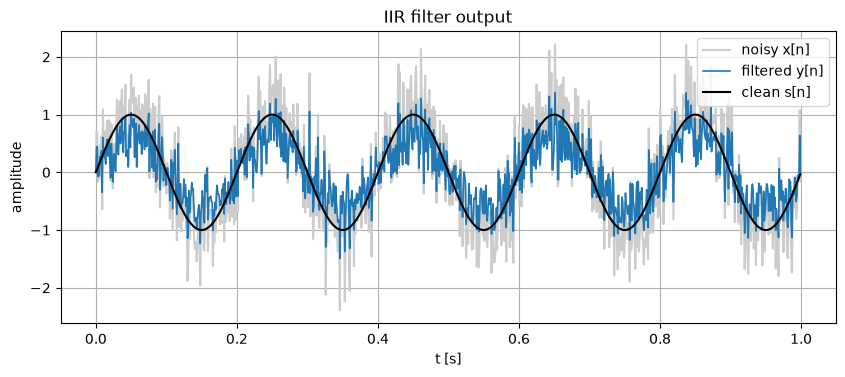

In [16]:
poles = np.roots(a_iir)
zeros = np.roots(b_iir)
print("poles:", poles, " |p| =", np.abs(poles))
print("zeros:", zeros)
print("stable:", bool(np.all(np.abs(poles) < 1)))

h_iir = iir_filter(np.r_[1, np.zeros(19)], b_iir, a_iir)
print("impulse response (first 8):", h_iir[:8])
print(f"|H| at 0 Hz:    {abs(gain(b_iir, a_iir, 0)):.4f}")
print(f"|H| at {f0} Hz:    {abs(gain(b_iir, a_iir, w0)):.4f}")
print(f"|H| at fs/2:    {abs(gain(b_iir, a_iir, np.pi)):.4f}")
h_long = iir_filter(np.r_[1, np.zeros(499)], b_iir, a_iir)
print(f"noise power gain sum(h^2): {np.sum(h_long**2):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
unit = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
ax[0].plot(unit.real, unit.imag, "k", lw=0.8)
ax[0].plot(poles.real, poles.imag, "rx", ms=10, mew=2, label="pole")
ax[0].plot(zeros.real, zeros.imag, "bo", ms=8, mfc="none", mew=2,
           label="zero")
ax[0].set_aspect("equal")
ax[0].set_xlabel("Re")
ax[0].set_ylabel("Im")
ax[0].set_title("IIR poles and zeros")
ax[0].legend()
ax[1].stem(np.arange(20), h_iir)
ax[1].set_xlabel("n")
ax[1].set_ylabel("h[n]")
ax[1].set_title("IIR impulse response")
fig.tight_layout()
fig.savefig(figures / "iir_poles_impulse.png", dpi=150)
plt.show()

plot_response(b_iir, a_iir, "IIR", "iir")
plot_output(y_iir, "IIR filter output", "iir")

### Adaptive LMS filter, $\mu = 0.05$, $M = 6$

lambda_max = 3.3149
stability bound 2/lambda_max = 0.6033, mu = 0.05
final weights: [0.0606 0.0621 0.0675 0.0668 0.0778 0.0934]


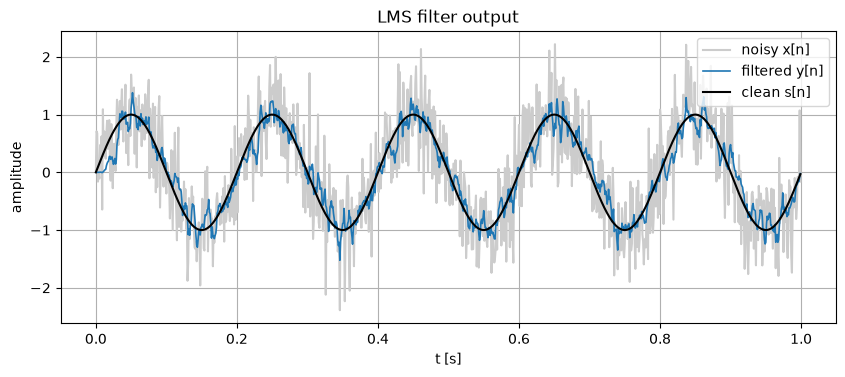

In [17]:
X = np.array([x[n - M + 1:n + 1][::-1] for n in range(M - 1, len(x))])
R = X.T @ X / len(X)
lam_max = np.linalg.eigvalsh(R).max()
print(f"lambda_max = {lam_max:.4f}")
print(f"stability bound 2/lambda_max = {2 / lam_max:.4f}, mu = {mu}")

y_lms, e_lms, w_lms, w_hist = lms_filter(x, s, mu, M)
print("final weights:", w_lms)

plot_output(y_lms, "LMS filter output", "lms")

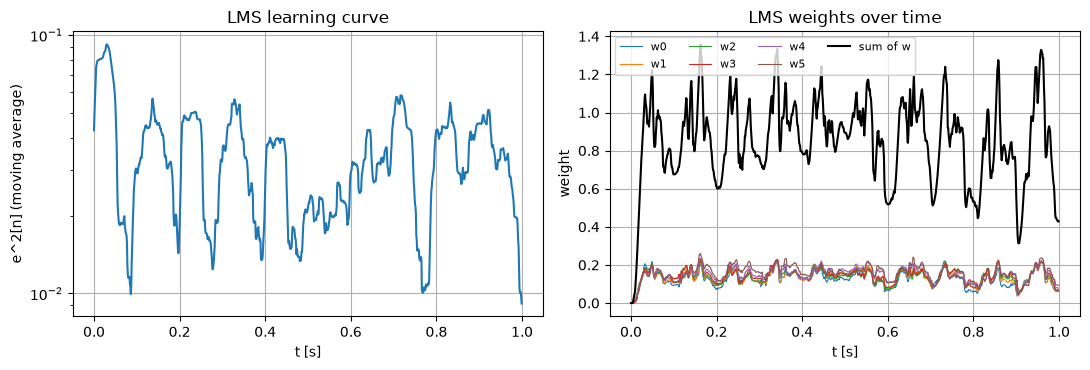

sum of weights in the 2nd half: min 0.313, max 1.329, mean 0.833


In [18]:
window = 50
mse_curve = np.convolve(e_lms**2, np.ones(window) / window, mode="same")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(t, mse_curve)
ax[0].set_xlabel("t [s]")
ax[0].set_ylabel("e^2[n] (moving average)")
ax[0].set_title("LMS learning curve")
for i in range(M):
    ax[1].plot(t, w_hist[:, i], lw=0.8, label=f"w{i}")
ax[1].plot(t, w_hist.sum(axis=1), "k", lw=1.5, label="sum of w")
ax[1].set_xlabel("t [s]")
ax[1].set_ylabel("weight")
ax[1].set_title("LMS weights over time")
ax[1].legend(ncol=4, fontsize=8)
fig.tight_layout()
fig.savefig(figures / "lms_learning.png", dpi=150)
plt.show()

second = slice(fs // 2, None)
total = w_hist[second].sum(axis=1)
print(f"sum of weights in the 2nd half: min {total.min():.3f}, "
      f"max {total.max():.3f}, mean {total.mean():.3f}")

### Comparison

In [19]:
def lti_snr(b, a):
    return snr_db(signal.lfilter(b, a, s), signal.lfilter(b, a, v))


b_norm = b_fir / b_fir.sum()
y_norm = fir_filter(x, b_norm)
mse_lms = np.mean((y_lms[second] - s[second])**2)

rows = [
    ("noisy input", np.mean((x - s)**2), snr_db(s, v)),
    ("FIR", np.mean((y_fir - s)**2), lti_snr(b_fir, [1])),
    ("FIR, b / sum(b)", np.mean((y_norm - s)**2), lti_snr(b_norm, [1])),
    ("IIR", np.mean((y_iir - s)**2), lti_snr(b_iir, a_iir)),
    ("LMS", mse_lms, 10 * np.log10(np.mean(s**2) / mse_lms)),
]

print(f"{'signal':18s} {'MSE':>8s} {'SNR [dB]':>9s}")
for name, mse, snr in rows:
    print(f"{name:18s} {mse:8.4f} {snr:9.2f}")

signal                  MSE  SNR [dB]
noisy input          0.2505      3.00
FIR                  0.3664      4.26
FIR, b / sum(b)      0.1881      4.26
IIR                  0.1530      3.53
LMS                  0.0323     11.90


In [20]:
seeds = range(20)
results = {"noisy": [], "FIR": [], "IIR": [], "LMS": []}
for seed in seeds:
    noise = sigma * np.random.default_rng(seed).standard_normal(fs)
    xs = s + noise
    ys, _, _, _ = lms_filter(xs, s, mu, M)
    results["noisy"].append(np.mean(noise**2))
    results["FIR"].append(np.mean((fir_filter(xs, b_fir) - s)**2))
    results["IIR"].append(np.mean((iir_filter(xs, b_iir, a_iir) - s)**2))
    results["LMS"].append(np.mean((ys[second] - s[second])**2))

print(f"MSE over {len(seeds)} noise realisations (mean +- std):")
for name, values in results.items():
    print(f"{name:6s} {np.mean(values):.4f} +- {np.std(values):.4f}")

MSE over 20 noise realisations (mean +- std):
noisy  0.2470 +- 0.0095
FIR    0.3632 +- 0.0166
IIR    0.1541 +- 0.0068
LMS    0.0343 +- 0.0039


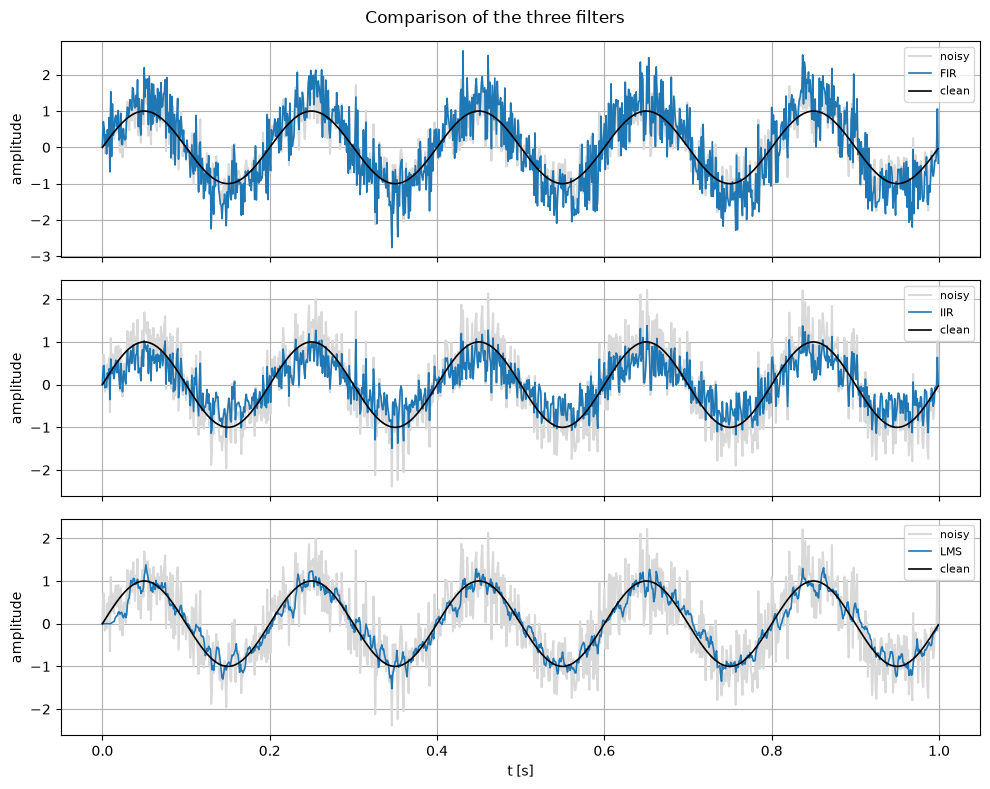

In [21]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for axis, y, name in zip(ax, [y_fir, y_iir, y_lms], ["FIR", "IIR", "LMS"]):
    axis.plot(t, x, color="0.85", label="noisy")
    axis.plot(t, y, "C0", lw=1.2, label=name)
    axis.plot(t, s, "k", lw=1.2, label="clean")
    axis.set_ylabel("amplitude")
    axis.legend(loc="upper right", fontsize=8)
ax[-1].set_xlabel("t [s]")
fig.suptitle("Comparison of the three filters")
fig.tight_layout()
fig.savefig(figures / "comparison.png", dpi=150)
plt.show()